In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix ,  roc_curve, auc

from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
import warnings
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

from sklearn.metrics import confusion_matrix

from sklearn.preprocessing import label_binarize

import plotly.express as px
from sklearn.decomposition import PCA


In [48]:
df=pd.read_csv('sdss_star_galaxy_qso.csv')
df

,u,g,r,i,z,class,redshift
0,18.96574,17.49392,16.80027,16.58460,16.32055,STAR,0.000022
1,18.87810,17.18946,16.36462,16.03709,15.80739,STAR,0.000102
2,24.89331,24.84063,24.07477,21.93128,20.56525,QSO,0.205156
3,18.80745,17.31809,17.08153,17.01195,16.92199,STAR,0.000252
4,20.07667,18.26777,17.52306,17.19679,16.90737,STAR,-0.000049
...,...,...,...,...,...,...,...
9995,18.09561,16.98192,16.59340,16.46099,16.39521,STAR,0.000069
9996,16.63280,15.10377,14.54745,14.36910,14.29143,STAR,-0.000039
9997,17.79499,17.50262,17.84578,18.12200,18.36795,STAR,0.000202
9998,20.91481,18.74681,17.48831,16.96554,16.55446,GALAXY,0.165487


In [49]:
df.replace(-9999, np.nan, inplace=True)
df.replace([-9999, -9999.0], np.nan, inplace=True)

In [50]:
df.isnull().sum()

,0
u,26
g,25
r,21
i,22
z,24
class,0
redshift,0


In [51]:
df.fillna(df.median(numeric_only=True), inplace=True)
df.isna().sum()

,0
u,0
g,0
r,0
i,0
z,0
class,0
redshift,0


In [52]:
check_values = [-9999, 9999]
if (df.isin(check_values)).any().any():
    print(f"The DataFrame still contains values from {check_values}.")

else:
    print(f"The DataFrame does not contain values from {check_values}.")

The DataFrame does not contain values from [-9999, 9999].


In [53]:
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])

df.head()

,u,g,r,i,z,class,redshift
0,18.96574,17.49392,16.80027,16.58460,16.32055,2,0.000022
1,18.87810,17.18946,16.36462,16.03709,15.80739,2,0.000102
2,24.89331,24.84063,24.07477,21.93128,20.56525,1,0.205156
3,18.80745,17.31809,17.08153,17.01195,16.92199,2,0.000252
4,20.07667,18.26777,17.52306,17.19679,16.90737,2,-0.000049


In [54]:
X = df.drop('class', axis=1)   # Features
y = df['class']

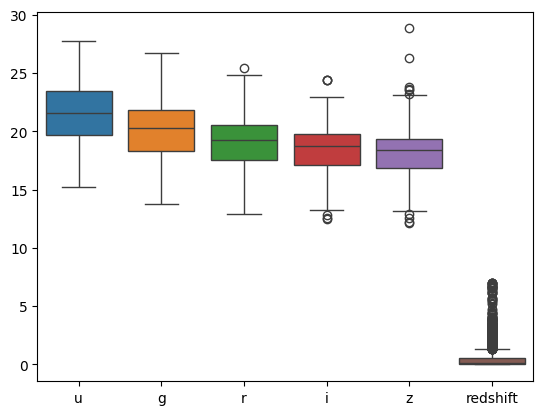

In [55]:
sns.boxplot(data=df[['u','g','r','i','z','redshift']])
plt.show()

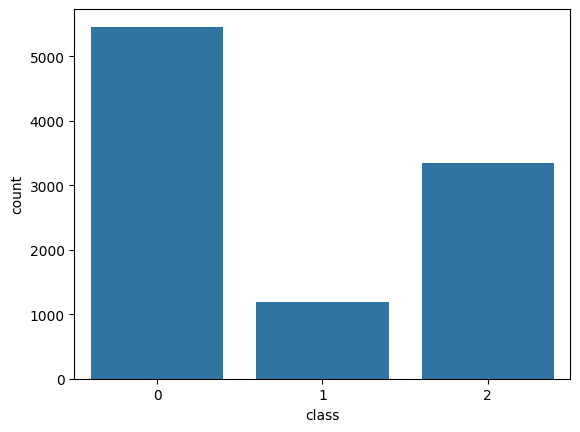

In [56]:
sns.countplot(x='class', data=df)
plt.show()

In [57]:
le = LabelEncoder()
y = le.fit_transform(y)

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [59]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [60]:
y_pred = rf.predict(X_test)


In [61]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9865


In [62]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1082
           1       0.99      0.93      0.96       236
           2       0.99      1.00      0.99       682

    accuracy                           0.99      2000
   macro avg       0.99      0.97      0.98      2000
weighted avg       0.99      0.99      0.99      2000



In [63]:
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier(random_state=42)
svm = SVC(probability=True)

In [64]:
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

In [65]:
voting = VotingClassifier(
    estimators=[
        ('knn', knn),
        ('dt', dt),
        ('svm', svm)
    ],
    voting='soft'
)

In [66]:
voting.fit(X_train, y_train)

VotingClassifier(estimators=[('knn', KNeighborsClassifier()),
                             ('dt', DecisionTreeClassifier(random_state=42)),
                             ('svm', SVC(probability=True))],
                 voting='soft')

In [67]:
y_predv = voting.predict(X_test)

In [68]:
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Voting Ensemble Accuracy:", accuracy_score(y_test, y_predv))

KNN Accuracy: 0.937
Decision Tree Accuracy: 0.972
SVM Accuracy: 0.8485
Voting Ensemble Accuracy: 0.965


In [69]:
Scaler=StandardScaler()
X_Tr_scaled=Scaler.fit_transform(X_train)
X_Te_scaled=Scaler.transform(X_test)
X_Tr_scaled
X_Te_scaled

array([[-1.81948462, -1.89810179, -1.91540648, -1.86684383, -1.70120753,
        -0.58670587],
       [ 1.00821317,  0.85536112,  0.62815161,  0.49270169,  0.43580127,
         0.12555552],
       [ 0.83840912,  0.44280082,  0.73391958,  0.97364524,  1.0532492 ,
        -0.58677703],
       ...,
       [ 0.83850339,  0.83632338,  1.31900815,  1.84355632,  1.93241201,
         3.6942372 ],
       [ 0.80478426,  0.72355315,  0.36915063, -0.17109829, -0.51668231,
        -0.58711174],
       [-0.96946169, -0.95615666, -0.84153621, -0.69913427, -0.57395793,
        -0.58656947]])

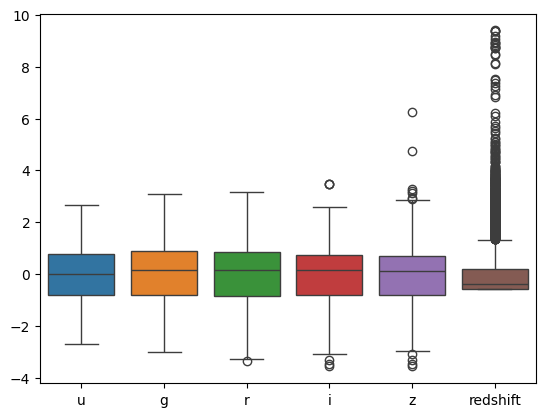

In [70]:
X_Tr_scaled_df = pd.DataFrame(X_Tr_scaled, columns=X.columns)
sns.boxplot(data=X_Tr_scaled_df[['u','g','r','i','z','redshift']])
plt.show()

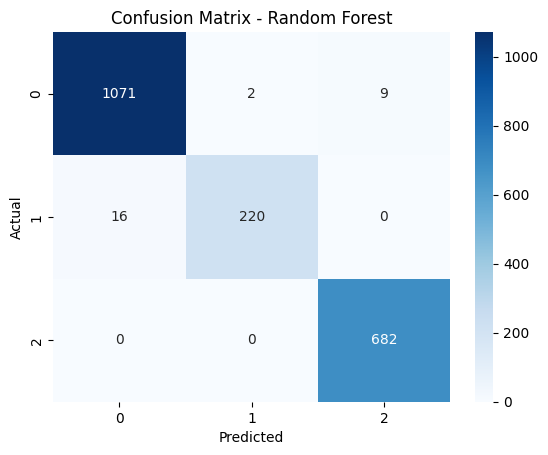

In [71]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

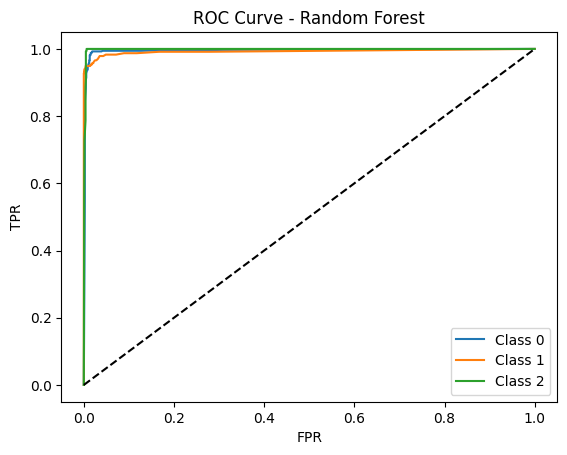

In [72]:


y_test_bin = label_binarize(y_test, classes=[0,1,2])
y_score = rf.predict_proba(X_test)

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"Class {i}")

plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve - Random Forest")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

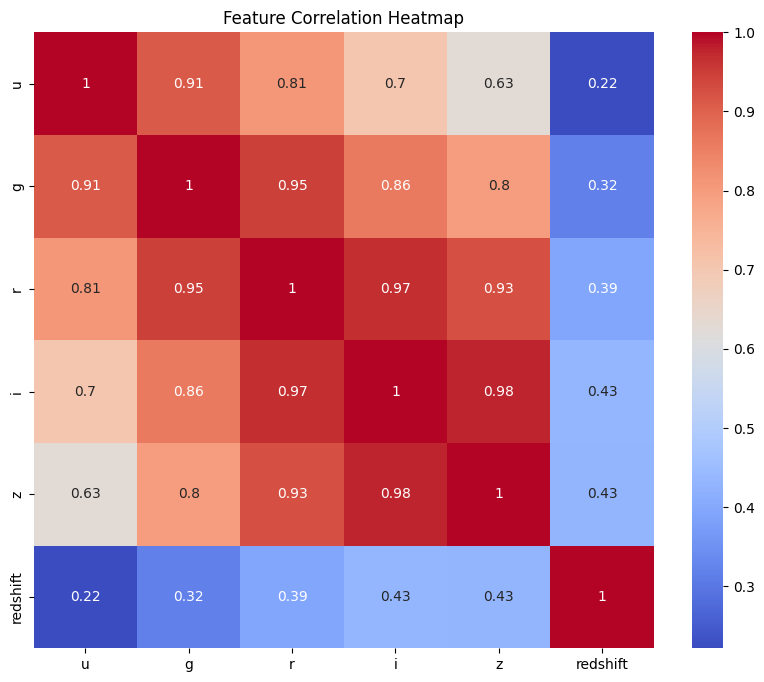

In [73]:


plt.figure(figsize=(10,8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

In [74]:

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])

pca_df['class'] = y

In [75]:
print("Explained Variance:", pca.explained_variance_ratio_)

Explained Variance: [0.8569106  0.10555766 0.02034688]


In [76]:

label_map = {0: "Star", 1: "Galaxy", 2: "Quasar"}
pca_df['class_name'] = pca_df['class'].map(label_map)

fig = px.scatter_3d(
    pca_df,
    x='PC1',
    y='PC2',
    z='PC3',
    color='class_name',
    title="3D Space of Celestial Objects "
)

fig.show()

In [77]:
pca = PCA(n_components=3)
X_test_pca = pca.fit_transform(X_test)

In [78]:
pca_df = pd.DataFrame(X_test_pca, columns=['PC1','PC2','PC3'])

pca_df['actual'] = y_test
pca_df['predicted'] = y_pred

In [79]:
pca_df['correct'] = pca_df['actual'] == pca_df['predicted']

In [80]:
fig = px.scatter_3d(
    pca_df,
    x='PC1',
    y='PC2',
    z='PC3',
    color='correct',
    title="Correct vs Wrong Predictions"
)

fig.show()

In [81]:
pca_df['size'] = pca_df['correct'].apply(lambda x: 5 if x else 10)

fig = px.scatter_3d(
    pca_df,
    x='PC1',
    y='PC2',
    z='PC3',
    color='actual',
    symbol='correct',
    size='size',
    title="ML Prediction Analysis "
)

fig.show()

In [82]:
label_map = {0: "Star", 1: "Galaxy", 2: "Quasar"}

In [83]:
x = np.linspace(pca_df['PC1'].min(), pca_df['PC1'].max(), 20)
y = np.linspace(pca_df['PC2'].min(), pca_df['PC2'].max(), 20)
z = np.linspace(pca_df['PC3'].min(), pca_df['PC3'].max(), 20)

grid = np.array(np.meshgrid(x, y, z)).T.reshape(-1, 3)

grid_df = pd.DataFrame(grid, columns=['PC1','PC2','PC3'])

Model comparison


In [84]:

pca_df['rf_pred'] = rf.predict(X_test)
pca_df['knn_pred'] = knn.predict(X_test)
pca_df['svm_pred'] = svm.predict(X_test)

label_map = {0: "Star", 1: "Galaxy", 2: "Quasar"}
pca_df['class_name'] = pca_df['actual'].map(label_map)
pca_df.to_json("space_data.json", orient="records")
